# Notebook 03: Advanced Models (BiLSTM, CNN-LSTM)
## Graduation Thesis: CNN-BiLSTM-Attention Model for Electricity Load Forecasting in a Microgrid

**Advanced Models:**
1. BiLSTM (Bidirectional LSTM)
2. CNN-LSTM

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os, json, joblib, warnings
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (LSTM, Bidirectional, Dense, Dropout,
                                     Conv1D, MaxPooling1D, Flatten, Input)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from helpers import inverse_transform_target, calculate_metrics, plot_training_history, plot_predictions

warnings.filterwarnings('ignore')
tf.random.set_seed(42)
np.random.seed(42)

PROJECT_DIR = os.getcwd()
DATA_DIR = os.path.join(PROJECT_DIR, 'data')
MODELS_DIR = os.path.join(PROJECT_DIR, 'models')
RESULTS_DIR = os.path.join(PROJECT_DIR, 'results')

data = np.load(os.path.join(DATA_DIR, 'processed_data.npz'))
X_train, y_train = data['X_train'], data['y_train']
X_val, y_val = data['X_val'], data['y_val']
X_test, y_test = data['X_test'], data['y_test']

with open(os.path.join(DATA_DIR, 'config.json')) as f:
    config = json.load(f)

scaler = joblib.load(os.path.join(DATA_DIR, 'scaler.pkl'))
TARGET_IDX = config['TARGET_IDX']
n_features = config['n_features']

callbacks = [
    EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6)
]

print(f'X_train: {X_train.shape}')
print(f'X_test: {X_test.shape}')

X_train: (12115, 48, 37)
X_test: (2559, 48, 37)


## 1. BiLSTM Model

In [2]:
model_bilstm = Sequential([
    Bidirectional(LSTM(128, return_sequences=True), input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2),
    Bidirectional(LSTM(64, return_sequences=False)),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1)
])

model_bilstm.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mse')
model_bilstm.summary()

history_bilstm = model_bilstm.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100, batch_size=32,
    callbacks=callbacks, verbose=1
)

model_bilstm.save(os.path.join(MODELS_DIR, 'bilstm_model.keras'))
print('BiLSTM model saved!')

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 48, 256)        │       169,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 48, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 338,497 (1.29 MB)

 Trainable params: 338,497 (1.29 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100


... (6,907 outputs left out)


377/379 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 2.0799e-04


379/379 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 2.0807e-04


379/379 ━━━━━━━━━━━━━━━━━━━━ 13s 34ms/step - loss: 2.2198e-04 - val_loss: 3.8970e-04 - learning_rate: 3.1250e-05


BiLSTM model saved!


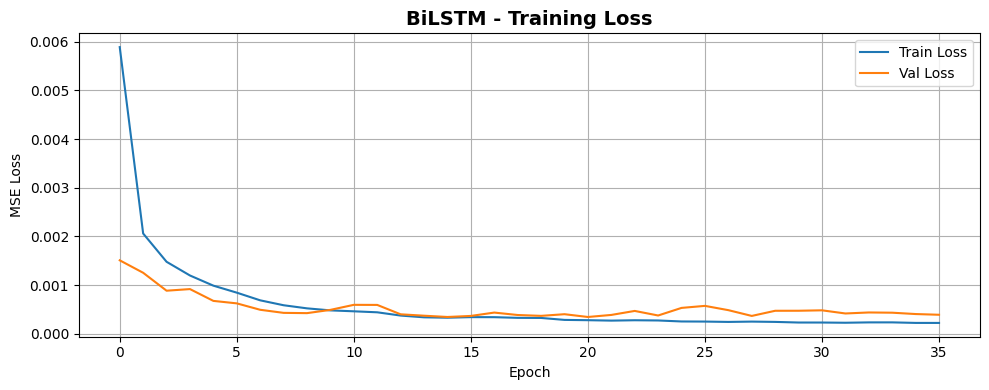


 1/80 ━━━━━━━━━━━━━━━━━━━━ 29s 373ms/step


 5/80 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step  


 9/80 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


13/80 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


17/80 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


21/80 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step

... (13 outputs left out)


77/80 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step


80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step


=== BiLSTM Results ===
  MAE: 46.1122
  RMSE: 66.9741
  MAPE: 0.8609
  R2: 0.9838


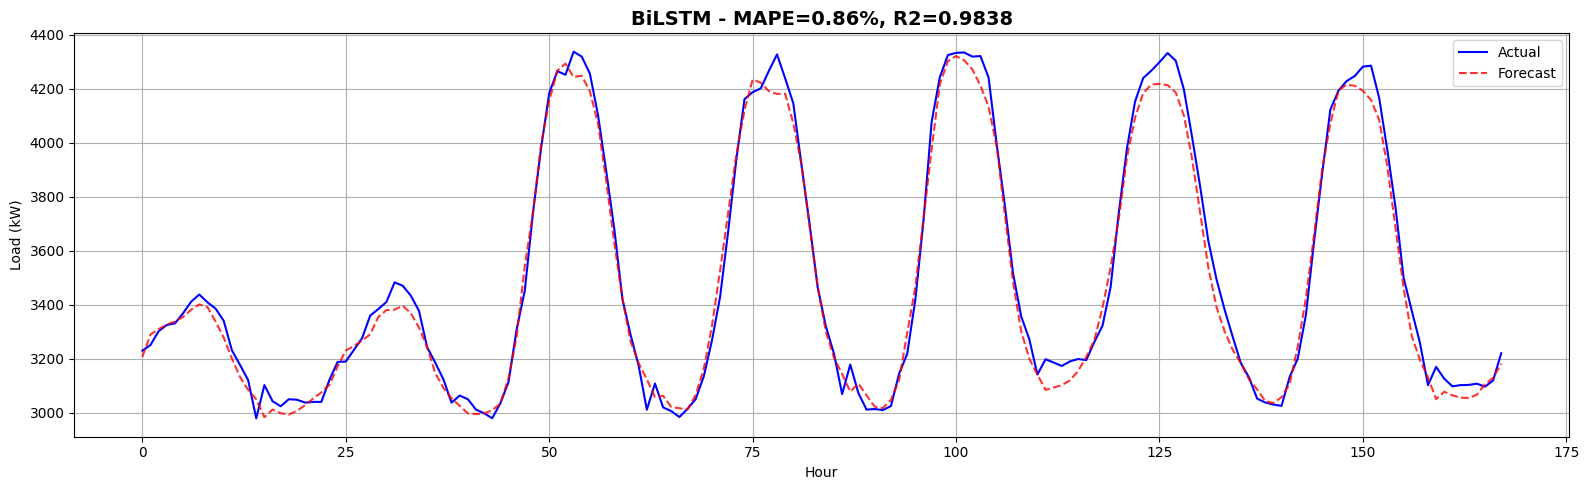

In [3]:
plot_training_history(history_bilstm, 'BiLSTM')

y_pred_bilstm = model_bilstm.predict(X_test).flatten()
y_true_real = inverse_transform_target(y_test, scaler, TARGET_IDX, n_features)
y_pred_bilstm_real = inverse_transform_target(y_pred_bilstm, scaler, TARGET_IDX, n_features)

metrics_bilstm = calculate_metrics(y_true_real, y_pred_bilstm_real)
print('=== BiLSTM Results ===')
for k, v in metrics_bilstm.items():
    print(f'  {k}: {v:.4f}')

plot_predictions(y_true_real, y_pred_bilstm_real, 'BiLSTM')

## 2. CNN-LSTM Model

In [4]:
model_cnn_lstm = Sequential([
    Conv1D(64, kernel_size=3, activation='relu', padding='same',
           input_shape=(X_train.shape[1], X_train.shape[2])),
    Conv1D(64, kernel_size=3, activation='relu', padding='same'),
    MaxPooling1D(pool_size=2),
    LSTM(128, return_sequences=True),
    Dropout(0.2),
    LSTM(64, return_sequences=False),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1)
])

model_cnn_lstm.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mse')
model_cnn_lstm.summary()

history_cnn_lstm = model_cnn_lstm.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100, batch_size=32,
    callbacks=callbacks, verbose=1
)

model_cnn_lstm.save(os.path.join(MODELS_DIR, 'cnn_lstm_model.keras'))
print('CNN-LSTM model saved!')

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 48, 64)         │         7,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 48, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 24, 128)        │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 24, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 169,857 (663.50 KB)

 Trainable params: 169,857 (663.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100


... (1,539 outputs left out)


374/379 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 2.9206e-04


378/379 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 2.9214e-04


379/379 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - loss: 3.0002e-04 - val_loss: 8.5834e-04 - learning_rate: 2.5000e-04


CNN-LSTM model saved!


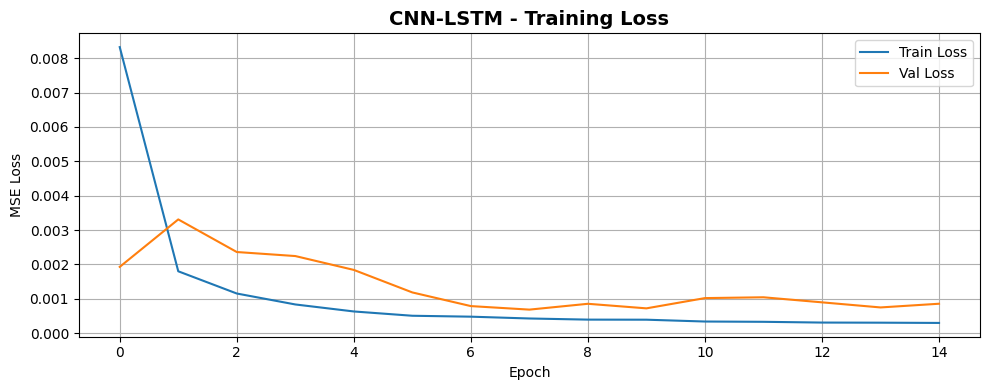


 1/80 ━━━━━━━━━━━━━━━━━━━━ 18s 232ms/step


 9/80 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step   


16/80 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step


23/80 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step


30/80 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step


36/80 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step

... (5 outputs left out)


76/80 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step


80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step


=== CNN-LSTM Results ===
  MAE: 131.5437
  RMSE: 160.9313
  MAPE: 3.3789
  R2: 0.9063


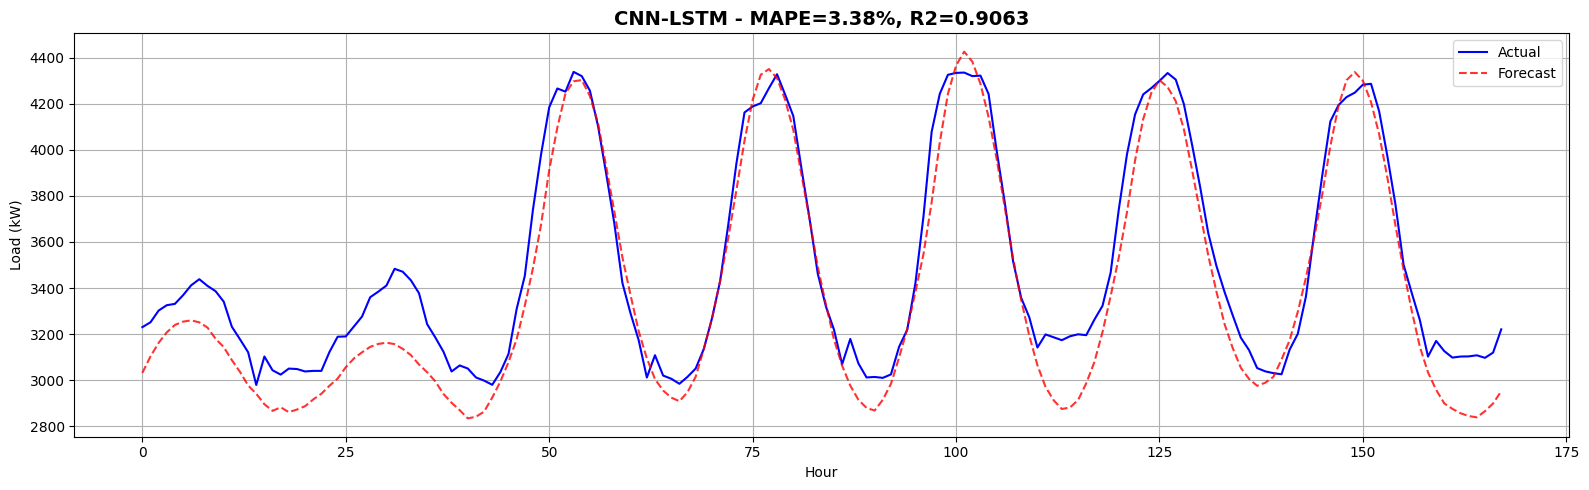

In [5]:
plot_training_history(history_cnn_lstm, 'CNN-LSTM')

y_pred_cnn_lstm = model_cnn_lstm.predict(X_test).flatten()
y_pred_cnn_lstm_real = inverse_transform_target(y_pred_cnn_lstm, scaler, TARGET_IDX, n_features)

metrics_cnn_lstm = calculate_metrics(y_true_real, y_pred_cnn_lstm_real)
print('=== CNN-LSTM Results ===')
for k, v in metrics_cnn_lstm.items():
    print(f'  {k}: {v:.4f}')

plot_predictions(y_true_real, y_pred_cnn_lstm_real, 'CNN-LSTM')

## 3. Summary of Results

                 MAE        RMSE      MAPE        R2
LSTM       34.878381   57.592798  0.363839  0.988001
BiLSTM     46.112173   66.974105  0.860896  0.983773
CNN-LSTM  131.543711  160.931331  3.378892  0.906308
GRU       132.426656  160.468353  3.429379  0.906847


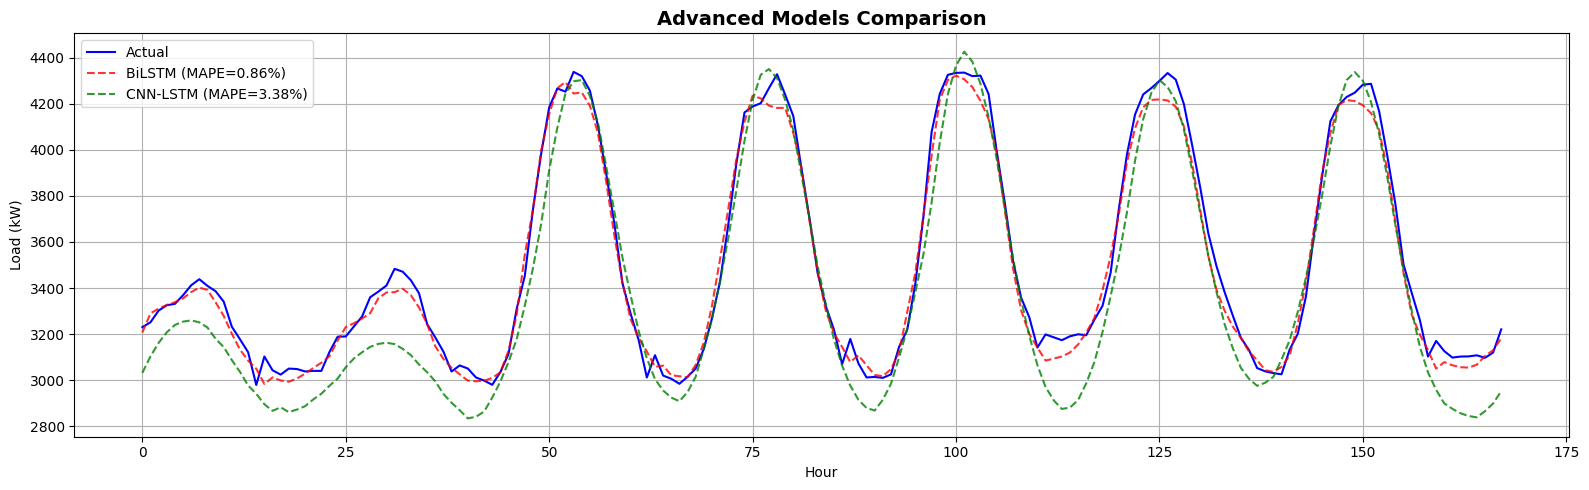


Notebook 03 hoàn tất! Tiếp theo: 04_Proposed_Model.ipynb


In [ ]:
# Load baseline results
baseline_df = pd.read_csv(os.path.join(RESULTS_DIR, 'baseline_results.csv'), index_col=0)

# Combine all
advanced_df = pd.DataFrame([metrics_bilstm, metrics_cnn_lstm], index=['BiLSTM', 'CNN-LSTM'])
all_results = pd.concat([baseline_df, advanced_df])
all_results.to_csv(os.path.join(RESULTS_DIR, 'all_results_nb03.csv'))
print(all_results.sort_values('MAPE'))

# Save predictions
np.savez_compressed(
    os.path.join(RESULTS_DIR, 'advanced_predictions.npz'),
    y_true=y_true_real,
    y_pred_bilstm=y_pred_bilstm_real,
    y_pred_cnn_lstm=y_pred_cnn_lstm_real
)

# Comparison plot
fig, ax = plt.subplots(figsize=(16, 5))
n = 168
ax.plot(range(n), y_true_real[:n], 'b-', label='Actual', linewidth=1.5)
ax.plot(range(n), y_pred_bilstm_real[:n], 'r--', label=f'BiLSTM (MAPE={metrics_bilstm["MAPE"]:.2f}%)', alpha=0.8)
ax.plot(range(n), y_pred_cnn_lstm_real[:n], 'g--', label=f'CNN-LSTM (MAPE={metrics_cnn_lstm["MAPE"]:.2f}%)', alpha=0.8)
ax.set_title('Advanced Models Comparison', fontsize=14, fontweight='bold')
ax.set_xlabel('Hour')
ax.set_ylabel('Load (kW)')
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'advanced_comparison.png'), dpi=150)
plt.show()


print('\nNotebook 03 completed! Next: 04_Proposed_Model.ipynb')